<a href="https://colab.research.google.com/github/ravishanilmani/2026_Intro_Python/blob/main/FEEDBACK_ravishanilmani.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-I/1.5-pandas-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import pandas as `pd` and numpy as `np`, seed any randomness with `default_rng`, and keep units in your column names.

## Exercise 1: Earthquake data analysis

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/usgs-2014-south-napa-earthquake.jpg" alt="A dirt track through a vineyard, broken along its length by a continuous ridge of pushed-up soil following the fault trace" width="800">

<em>Surface rupture from the magnitude 6.0 South Napa earthquake of 24 August 2014 — the kind of event a row in this catalog stands for. The continuous "mole track" running parallel to the strike of the fault indicates some east–west compression on top of the <a href="https://www.usgs.gov/faqs/what-fault-and-what-are-different-types">right-lateral faulting</a>; taken near Buhman Road. Photo <a href="https://www.usgs.gov/media/images/2014-south-napa-ca-m6-earthquake-august-24-6">USGS</a>, public domain.</em>


This exercise reviews the `pandas` fundamentals of this subchapter on one real catalog, covering how to

* open csv files
* manipulate dataframe indexes
* parse date columns
* examine basic dataframe statistics
* manipulate text columns and extract values
* plot dataframe contents using
  * bar charts
  * histograms
  * scatter plots

The data is a snapshot of the [USGS Earthquakes Database](https://earthquake.usgs.gov/earthquakes/search/): every event recorded worldwide in 2014, 120 108 rows.

You do not need to download the file yourself. The pre-supplied cell below fetches and caches it with the help of [pooch](https://www.fatiando.org/pooch/latest/) — there is no need to read pooch's documentation unless you want to — and stores the path to the file in the variable `datafile`.

In [2]:
# Pre-supplied: download and cache the earthquake data.
import pooch

datafile = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/usgs_earthquakes_2014.csv",
    known_hash="sha256:84d455fb96dc8f782fba4b5fbe56cb8970cab678f07c766fcba1b1c4674de1b1",
    fname="usgs_earthquakes_2014.csv",
    path=pooch.os_cache("mlees"),
)

**ℹ️ Beyond this subchapter**

The tools below were not demonstrated in 1.5's lecture. Each question links its documentation where
it is needed; they are collected here so you know when you are being asked to read a new page rather
than to recall one:

- [`nlargest`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nlargest.html) — Q5
- [pandas' text data functions](https://pandas.pydata.org/pandas-docs/stable/user_guide/text.html), and [`Series.str.split`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.split.html) in particular — Q6
- [`unique`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.unique.html) — Q7
- [`count`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.count.html) and [`value_counts`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html) — Q9

The scatter plot and colorbar in Q11 are the ones from 1.4.6. Everything else the questions ask for
is from this subchapter's lecture: `read_csv` with date-parsed columns, `set_index`, `.head()`,
`.info()`, `.describe()`, boolean filtering, `.index` and `.values`, `kind="bar"`, `kind="hist"`, and
a logarithmic count axis.

**Q1) First, import `numpy`, `pandas` and `matplotlib`, and — optionally — set the display options.**

Hint: display options are documented [at this link](https://pandas.pydata.org/pandas-docs/stable/user_guide/options.html).

In [3]:
# Import all libraries here
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", "{:.2f}".format)
np.set_printoptions(suppress=True, precision=4)


**Q2) Use pandas' `read_csv` function directly on `datafile` to open it as a `DataFrame`.**

Display the first few rows with `.head()`, and the column names, dtypes and non-null counts with
`.info()`. Check these tutorials if you have doubts about what the two functions do:
[`.head()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.head.html)
and
[`.info()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.info.html?highlight=info#pandas.DataFrame.info).

`.info()` will show you that the two date columns, `time` and `updated`, came in as plain strings
rather than as dates. They were not parsed automatically. What can you do about that?

In [5]:
# Open the file as a pandas DataFrame, then display the first few rows and the DataFrame info

df = pd.read_csv(datafile)

print("--- FIRST FEW ROWS ---")
print(df.head())

print("\n--- DATAFRAME INFO ---")
df.info()

#To convert the time and updated columns from plain strings into actual datetime objects,

#Option A: Parse them directly while loading

#Using the parse_dates argument inside read_csv to fix this automatically right at the start.
#python
# Pass a list of the column names you want parsed as dates
#df = pd.read_csv(datafile, parse_dates=["time", "updated"])


#Option B: Convert them after loading

#df["time"] = pd.to_datetime(df["time"])
#df["updated"] = pd.to_datetime(df["updated"])


--- FIRST FEW ROWS ---
                      time  latitude  longitude  depth  mag magType  nst    gap  dmin  rms net          id                   updated                              place        type
0  2014-01-31 23:53:37.000     60.25    -152.71  90.20 1.10      ml  NaN    NaN   NaN 0.29  ak  ak11155107  2014-02-05T19:34:41.515Z  26km S of Redoubt Volcano, Alaska  earthquake
1  2014-01-31 23:48:35.452     37.07    -115.13   0.00 1.33      ml 4.00 171.43  0.34 0.02  nn  nn00436847  2014-02-01T01:35:09.000Z            32km S of Alamo, Nevada  earthquake
2  2014-01-31 23:47:24.000     64.67    -149.25   7.10 1.30      ml  NaN    NaN   NaN 1.00  ak  ak11151142  2014-02-01T00:03:53.010Z   12km NNW of North Nenana, Alaska  earthquake
3  2014-01-31 23:30:54.000     63.19    -148.96  96.50 0.80      ml  NaN    NaN   NaN 1.07  ak  ak11151135  2014-01-31T23:41:25.007Z         22km S of Cantwell, Alaska  earthquake
4  2014-01-31 23:30:52.210     32.62    -115.69  10.59 1.34      ml 6.00 285.

**Q3) Re-read the data in such a way that both date columns are identified as dates and the earthquake ID is used as the index.**

Check with `.head()` and `.info()` that it worked: `time` and `updated` should now be
`datetime64` columns, and `id` should be the index rather than a column.

Hint: the documentation for `read_csv` is [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html?highlight=read_csv).

In [7]:
# Re-read the data parsing the dates and setting the 'id' column as the index
df = pd.read_csv(datafile, parse_dates=["time", "updated"], index_col="id")

# Verify the changes
print("--- FIRST FEW ROWS ---")
print(df.head())

print("\n--- DATAFRAME INFO ---")
df.info()


--- FIRST FEW ROWS ---
                              time  latitude  longitude  depth  mag magType  nst    gap  dmin  rms net                          updated                              place        type
id                                                                                                                                                                                    
ak11155107 2014-01-31 23:53:37.000     60.25    -152.71  90.20 1.10      ml  NaN    NaN   NaN 0.29  ak 2014-02-05 19:34:41.515000+00:00  26km S of Redoubt Volcano, Alaska  earthquake
nn00436847 2014-01-31 23:48:35.452     37.07    -115.13   0.00 1.33      ml 4.00 171.43  0.34 0.02  nn        2014-02-01 01:35:09+00:00            32km S of Alamo, Nevada  earthquake
ak11151142 2014-01-31 23:47:24.000     64.67    -149.25   7.10 1.30      ml  NaN    NaN   NaN 1.00  ak 2014-02-01 00:03:53.010000+00:00   12km NNW of North Nenana, Alaska  earthquake
ak11151135 2014-01-31 23:30:54.000     63.19    -148.96  96.50

**Q4) Use `describe` to get the basic statistics of all the columns.**

Hint: the documentation of `describe` is [at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html).

In [8]:
# Use the describe function
df_summary = df.describe(include="all")

print(df_summary)

                                 time  latitude  longitude     depth       mag magType      nst      gap     dmin       rms     net                              updated                                place        type
count                          120108 120108.00  120108.00 120107.00 120065.00  120065 59688.00 94935.00 85682.00 119716.00  120108                               120108                               120108      120108
unique                            NaN       NaN        NaN       NaN       NaN      18      NaN      NaN      NaN       NaN      14                                  NaN                                45395          11
top                               NaN       NaN        NaN       NaN       NaN      ml      NaN      NaN      NaN       NaN      ak                                  NaN  10km E of Mammoth Lakes, California  earthquake
freq                              NaN       NaN        NaN       NaN       NaN   57608      NaN      NaN      NaN       NaN   31

**Q5) Use `nlargest` to get the top 20 earthquakes by magnitude.**

Hint: the documentation of `nlargest` is [at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nlargest.html).

In [9]:
# Use nlargest
top_20_earthquakes = df.nlargest(20, "mag")

print(top_20_earthquakes)

                              time  latitude  longitude  depth  mag magType  nst    gap  dmin  rms net                          updated                                    place        type
id                                                                                                                                                                                          
usc000nzvd 2014-04-01 23:46:47.260    -19.61     -70.77  25.00 8.20     mww  NaN  23.00  0.61 0.66  us 2015-07-30 16:24:51.223000+00:00                94km NW of Iquique, Chile  earthquake
usc000rki5 2014-06-23 20:53:09.700     51.85     178.74 109.00 7.90     mww  NaN  22.00  0.13 0.71  us 2015-04-18 21:54:08.699000+00:00  19km SE of Little Sitkin Island, Alaska  earthquake
usc000p27i 2014-04-03 02:43:13.110    -20.57     -70.49  22.40 7.70     mww  NaN  44.00  1.03 0.82  us 2015-06-06 07:31:05.755000+00:00                53km SW of Iquique, Chile  earthquake
usc000phx5 2014-04-12 20:14:39.300    -11.27     162.15

**Q6) Extract the state or country using pandas' text data functions, and add it as a new column to the `DataFrame`.**

Examine the column titled `place`: it holds strings like `"26km S of Redoubt Volcano, Alaska"`, so
it carries both the local description and the state or country. Pull the second part out and store
it in a new column called `country`.

Hint 1: the documentation for pandas' text data functions is [here](https://pandas.pydata.org/pandas-docs/stable/text.html).

Hint 2: you will use `.split()` to extract the country names. The documentation of this function
can be found [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.split.html?highlight=split#pandas.Series.str.split).

In [10]:
# Extract the state or country, and add it as a new column to the DataFrame called country
df["country"] = df["place"].str.split(",").str[-1].str.strip()
print(df[["place", "country"]].head())

#As aother way to do the above task the solution below can be used
#If a description has multiple commas (e.g., "10km NW of City, Region, Country"), using rsplit(',', n=1) splits from the right side exactly once,
#ensuring you only separate the very last part.

# Split from the right exactly once, and grab the second part (index 1)
#df["country"] = df["place"].str.rsplit(",", n=1).str[-1].str.strip()

                                        place country
id                                                   
ak11155107  26km S of Redoubt Volcano, Alaska  Alaska
nn00436847            32km S of Alamo, Nevada  Nevada
ak11151142   12km NNW of North Nenana, Alaska  Alaska
ak11151135         22km S of Cantwell, Alaska  Alaska
ci37171541       10km WNW of Progreso, Mexico  Mexico


**Q7) Display each unique value from the new `country` column.**

Hint: you may use the `unique` function documented [at this link](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.unique.html).

You should see an array of a couple of hundred country and state names. A plain split leaves the
space that followed the comma, so they come out as `array([' Alaska', ' Nevada', ...])` — worth
removing before you use them as labels.

In [11]:
# Display unique values
unique_countries = df["country"].unique()

print(unique_countries)

['Alaska' 'Nevada' 'Mexico' 'California' 'Papua New Guinea' 'New Zealand'
 'Missouri' 'South of the Fiji Islands' 'Montana' 'British Virgin Islands'
 'Washington' 'Oregon' 'Canada' 'Fiji' 'Wyoming' 'Antarctica' 'Chile'
 'Utah' 'Indonesia' 'Solomon Islands' 'Micronesia' 'Oklahoma' 'Hawaii'
 'Russia' 'Arizona' 'Philippines' 'Bolivia' 'Greece' 'Japan' 'Puerto Rico'
 'Iran' 'Tonga' 'Wallis and Futuna' 'Colorado' 'Guam' 'CA'
 'Carlsberg Ridge' 'Idaho' 'Pakistan'
 'Off the west coast of northern Sumatra' 'Burma' 'China' 'Peru'
 'Off the east coast of the North Island of New Zealand' 'Costa Rica'
 'Reykjanes Ridge' 'East Timor' 'Central East Pacific Rise'
 'Mid-Indian Ridge' 'Japan region' 'Northern Mariana Islands'
 'El Salvador' 'Samoa' 'Northern Mid-Atlantic Ridge' 'Taiwan' 'Arkansas'
 'South Sandwich Islands' 'Colombia' 'Dominican Republic' 'Argentina'
 'Texas' 'New Hampshire' 'Saint Helena' 'West of Vancouver Island'
 'Tanzania' 'Vanuatu' 'Bosnia and Herzegovina' 'India' 'American Samoa'

**Q8) Create a filtered dataset that only has earthquakes larger than magnitude 4.**

Hint: print the table to see the name of the column containing the earthquake magnitude.

Check out this [link](https://www.geeksforgeeks.org/ways-to-filter-pandas-dataframe-by-column-values/)
to find examples of filtering by column values.

In [12]:
# Filter the dataset based on the earthquakes' magnitudes
filtered_df = df[df["mag"] > 4]

print(filtered_df)

                              time  latitude  longitude  depth  mag magType  nst    gap  dmin  rms net                          updated                                              place        type                    country
id                                                                                                                                                                                                                               
usc000mqlp 2014-01-31 23:08:03.660     -4.98     153.95 110.18 4.20      mb  NaN  98.00  1.94 0.61  us        2014-04-08 01:43:19+00:00               115km ESE of Taron, Papua New Guinea  earthquake           Papua New Guinea
usc000mqln 2014-01-31 22:54:32.970    -28.18    -177.91  95.84 4.30      mb  NaN 104.00  1.06 1.14  us        2014-04-08 01:43:19+00:00               120km N of Raoul Island, New Zealand  earthquake                New Zealand
usc000mqls 2014-01-31 22:49:49.740    -23.12     179.12 528.34 4.40      mb  NaN  80.00  5.44 0.

**Q9) Using the filtered dataset (magnitude > 4), count the number of earthquakes whose magnitudes are above 4 [Num 1], and count the number of earthquakes in each country or state [Num 2]. Make a bar chart of Num 2 for the top 5 locations with the most earthquakes.**

Hint 1: to get Num 1, pandas has a `count` function documented
[at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.count.html).

Hint 2: check out the
[`value_counts`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)
function to get Num 2.

Then convert the first five rows of Num 2 into a `DataFrame` with two columns, `country` (text)
and `earthquake_num` (number), and recreate the bar chart below.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-top5-bar.png" alt="A bar chart of the number of magnitude-above-4 earthquakes in the five countries with the most of them" width="700">

<em>The five locations with the most magnitude-above-4 events in 2014.</em>

--- Top 5 Locations Counts ---
country
Indonesia           1911
Papua New Guinea    1290
Japan               1114
Chile                995
New Zealand          729
Name: count, dtype: int64


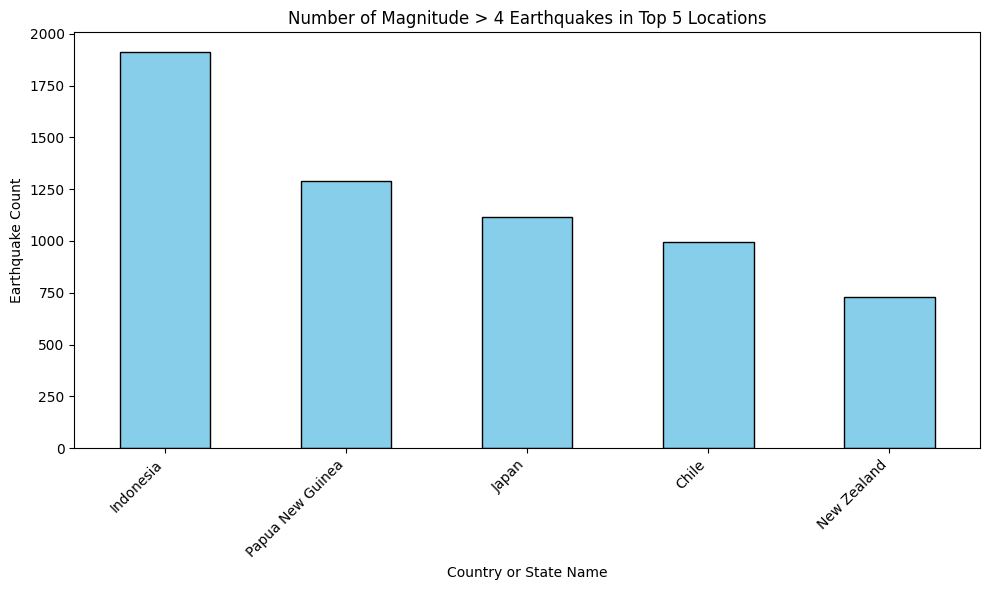

In [13]:

top_5_locations = filtered_df["country"].value_counts().head(5)

print("--- Top 5 Locations Counts ---")
print(top_5_locations)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
top_5_locations.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Number of Magnitude > 4 Earthquakes in Top 5 Locations")
plt.xlabel("Country or State Name")
plt.ylabel("Earthquake Count")
plt.ylim(bottom=0)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#As an alternative way of getting this plot is to use .groupby()
#instead of .value_counts()


#total_above_4 = len(filtered_df)

#top_5_df = (
    #filtered_df.groupby("country")
    #.size()
    #.sort_values(ascending=False)
    #.head(5)
    #.reset_index(name="earthquake_num")
#)

# Recreate the bar chart
#top_5_df.plot.bar(x="country", y="earthquake_num", color="seagreen", legend=False)
#plt.title("Number of Magnitude > 4 Earthquakes in Top 5 Locations")
#plt.ylabel("Number of Earthquakes")
#plt.xticks(rotation=0)
#plt.tight_layout()
#plt.show()



**Q10) Make a histogram for the distribution of the earthquakes' magnitudes.**

Hint: pandas has a histogram function documented
[at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html) and
matplotlib has one documented
[at this link](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.hist.html).

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-magnitude-hist.png" alt="A histogram of earthquake magnitude with a dashed grid" width="700">

<em>The distribution of magnitude across the whole catalog.</em>


Then redraw it with a logarithmic scale on the y-axis, which brings the rare large events into
view alongside the many small ones. Hint: here you can find a
[tutorial](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.yscale.html) for how to
change an axis scale.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-magnitude-hist-log.png" alt="The same histogram of earthquake magnitude with a logarithmic y-axis" width="700">

<em>The same histogram with a logarithmic count axis.</em>


Finally, make one histogram for the filtered dataset and one for the unfiltered dataset, side by
side.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-hist-filtered-unfiltered.png" alt="Two histograms of earthquake magnitude side by side, one for events above magnitude 4 and one for the whole catalog" width="100%">

<em>The filtered and unfiltered magnitude distributions, drawn on their own count axes.</em>

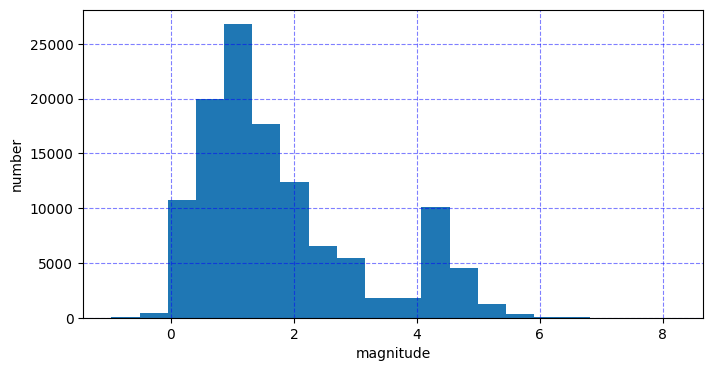

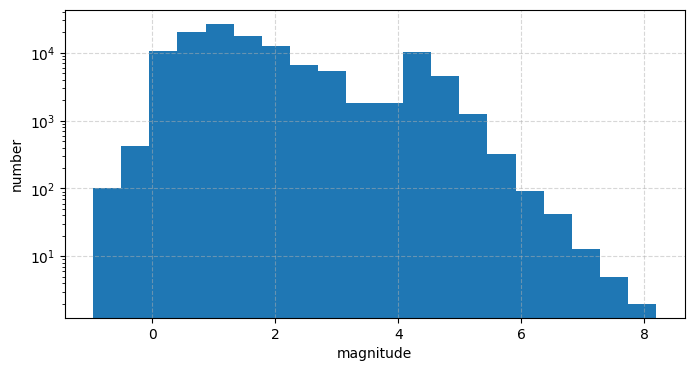

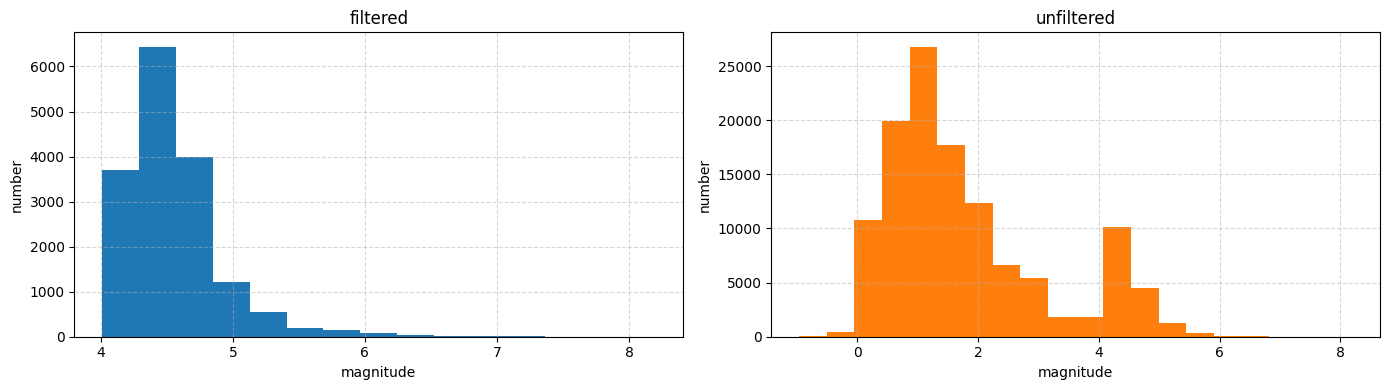

In [15]:
# Make the three histograms
#  histogram for the distribution of all earthquake magnitudes
plt.figure(figsize=(8, 4))
plt.hist(df["mag"], bins=20, edgecolor="none")
plt.xlabel("magnitude")
plt.ylabel("number")
plt.grid(True, linestyle="--", alpha=0.5, color="b" if "blue" else "gray")
plt.show()

#  histogram with a logarithmic scale on the y-axis
plt.figure(figsize=(8, 4))
plt.hist(df["mag"], bins=20, edgecolor="none")
plt.yscale("log")
plt.xlabel("magnitude")
plt.ylabel("number")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# side-by-side subplots (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Left plot: Filtered dataset (magnitudes > 4)
ax1.hist(filtered_df["mag"], bins=15, color="C0")
ax1.set_title("filtered")
ax1.set_xlabel("magnitude")
ax1.set_ylabel("number")
ax1.grid(True, linestyle="--", alpha=0.5)

# Right plot: Unfiltered dataset (all magnitudes)
ax2.hist(df["mag"], bins=20, color="C1")
ax2.set_title("unfiltered")
ax2.set_xlabel("magnitude")
ax2.set_ylabel("number")
ax2.grid(True, linestyle="--", alpha=0.5)

#
plt.tight_layout()
plt.show()

#When writing this code ,
#the biggest challenge was shifting from making one simple plot to making side-by-side plots.
#For a single plot, i used simple shortcuts like plt.xlabel(),
#but for side-by-side subplots, i must specifically tell Python which plot i am talking to by using commands like ax1.set_xlabel().
#If i mix these up,  labels will overlap or show up on the wrong graph.
#Another tricky part is switching to a log scale, because bins with zero earthquakes can sometimes cause rendering glitches
#since i cannot mathematically calculate a log value for zero.


**Q11) Visualise the locations of earthquakes by making a scatterplot of their latitude and longitude.**

Make a figure with two panels: one for the filtered dataset and one for the unfiltered one, with
the points coloured by magnitude on a shared colour range.

Hint: consider reading the documentation for
[`plt.scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) to make
the scatter plot and that of
[`plt.colorbar`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.colorbar.html) to
colour the points by magnitude. Pass the same `vmin` and `vmax` to both scatter calls, so that a
colour stands for the same magnitude in both panels.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-quake-scatter.png" alt="Two scatter plots of earthquake longitude against latitude coloured by magnitude, one filtered to magnitude above 4 and one unfiltered" width="100%">

<em>Every event in the catalog placed by longitude and latitude, filtered and unfiltered.</em>

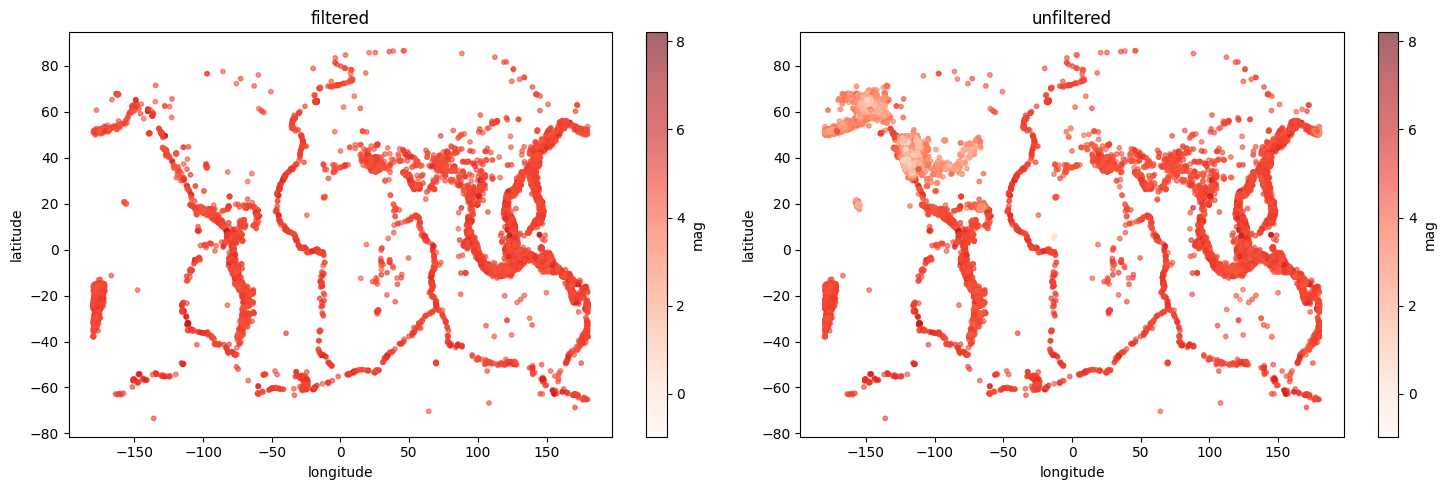

In [16]:
# Make the two scatter plots

vmin_val = df["mag"].min()
vmax_val = df["mag"].max()

# 2. Create the two-panel figure setup
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# --- Left Panel: Filtered Dataset ---
sc1 = ax1.scatter(
    filtered_df["longitude"],
    filtered_df["latitude"],
    c=filtered_df["mag"],
    cmap="Reds",
    vmin=vmin_val,
    vmax=vmax_val,
    s=10,
    alpha=0.6,
)
ax1.set_title("filtered")
ax1.set_xlabel("longitude")
ax1.set_ylabel("latitude")

# Create a dedicated colorbar for the filtered panel
cbar1 = fig.colorbar(sc1, ax=ax1)
cbar1.set_label("mag")

# --- Right Panel: Unfiltered Dataset ---
sc2 = ax2.scatter(
    df["longitude"],
    df["latitude"],
    c=df["mag"],
    cmap="Reds",
    vmin=vmin_val,
    vmax=vmax_val,
    s=10,
    alpha=0.6,
)
ax2.set_title("unfiltered")
ax2.set_xlabel("longitude")
ax2.set_ylabel("latitude")

# Create an identical colorbar for the unfiltered panel
cbar2 = fig.colorbar(sc2, ax=ax2)
cbar2.set_label("mag")

plt.tight_layout()
plt.show()


Do you notice a difference between the filtered and unfiltered datasets?

In [ ]:
#yes, there is a difference between the two datasets.
#The unfiltered map is dominated by minor regional activity caught by dense local seismograph networks,
#while the filtered map highlights only the larger,
#globally significant seismic events that trace active fault lines around the planet.